# Group theory 2: Cyclic groups

*Learning path: group theory, part 2 of 6.* [Index](README.md) · Previous: [Symmetry](01-symmetry.ipynb) · Next: [Permutations and Lagrange's theorem](03-permutations-and-lagrange.ipynb)

The simplest groups are made from a single element, repeated: the turns of a clock hand, the rotations of a regular
polygon, the remainders mod $n$. They are called **cyclic groups**, and they are where group theory meets the number
theory path. You will learn

* that rotations of an $n$-gon and addition mod $n$ are "the same group" (**isomorphic**),
* which elements **generate** the whole group, and what their orders are,
* the **subgroups** of a cyclic group, one for each divisor of $n$,
* the multiplication groups mod $n$, which are cyclic exactly when there is a primitive root,
* the complex **roots of unity** as a cyclic group.

## 1. Rotations and clock arithmetic

A regular hexagon has six rotations: by $0^\circ, 60^\circ, \ldots, 300^\circ$. With the corners numbered 1 to 6 around
the hexagon, the rotation by $60^\circ$ is the cycle $(1\ 2\ 3\ 4\ 5\ 6)$, and `generate` with that single element
lists all its powers:

In [1]:
R6 = generate(perm("(1 2 3 4 5 6)", 6))

[1, 2, 3, 4, 5, 6;
 2, 3, 4, 5, 6, 1;
 3, 4, 5, 6, 1, 2;
 4, 5, 6, 1, 2, 3;
 5, 6, 1, 2, 3, 4;
 6, 1, 2, 3, 4, 5]

> `generate`: All permutations made by composing the generators, one per row (the identity first); cayley(G) is the group table: entry (i, j) is the row number of G_i after G_j.

Row $k + 1$ is the rotation by $k \cdot 60^\circ$. Its group table (`cayley`, as in lesson 1: the entry in row $i$,
column $j$ is the row number of element $i$ after element $j$):

In [2]:
cayley(R6)

[1, 2, 3, 4, 5, 6;
 2, 3, 4, 5, 6, 1;
 3, 4, 5, 6, 1, 2;
 4, 5, 6, 1, 2, 3;
 5, 6, 1, 2, 3, 4;
 6, 1, 2, 3, 4, 5]

> `cayley` (see `generate`): All permutations made by composing the generators, one per row (the identity first); cayley(G) is the group table: entry (i, j) is the row number of G_i after G_j.

Now the addition table of the remainders $0, 1, \ldots, 5$ mod 6: the row for $k$ is `mod(k + [0 1 2 3 4 5], 6)`, the
sums $k + 0, \ldots, k + 5$ reduced mod 6.

In [3]:
table(mod(k + [0 1 2 3 4 5], 6), k, 0, 5)

[0, 1, 2, 3, 4, 5;
 1, 2, 3, 4, 5, 0;
 2, 3, 4, 5, 0, 1;
 3, 4, 5, 0, 1, 2;
 4, 5, 0, 1, 2, 3;
 5, 0, 1, 2, 3, 4]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

It is the same table with every entry one smaller: rotating by $a\cdot60^\circ$ and then $b\cdot60^\circ$ is rotating by
$(a + b)\cdot 60^\circ$, and after $360^\circ$ you start again, exactly like adding mod 6. Two groups whose tables match
after renaming the elements are **isomorphic**: they are the same group in different clothes. Every cyclic group with
$n$ elements is isomorphic to the remainders mod $n$ under addition, written $\mathbb{Z}_n$.

## 2. Orders and generators

The **order** of an element is the number of times you must repeat it to get back to the identity (lesson 1). In
$\mathbb{Z}_n$ the identity is 0 and "repeating $k$" means $k, 2k, 3k, \ldots$ mod $n$. You reach a multiple of $n$
after $n/\gcd(k, n)$ steps. The table lists $k$ and its order in $\mathbb{Z}_6$:

In [4]:
table([k, 6/gcd(k, 6)], k, 0, 5)

[0, 1;
 1, 6;
 2, 3;
 3, 2;
 4, 3;
 5, 6]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

The elements 1 and 5 have order 6: their multiples run through the whole group, so each of them **generates**
$\mathbb{Z}_6$. (Rotating by $300^\circ$ again and again also visits every position, just in the other direction.) In
general $k$ generates $\mathbb{Z}_n$ exactly when $\gcd(k, n) = 1$, so there are $\varphi(n)$ generators, Euler's
totient from the number theory path. For $n = 12$ (a clock):

In [5]:
iterate(mod(x + 5, 12), x, 0, 12)
iterate(mod(x + 4, 12), x, 0, 6)
totient(12)

[0, 5, 10, 3, 8, 1, 6, 11, 4, 9, 2, 7, 0]

> `iterate`: x0, f(x0), f(f(x0)), ...

[0, 4, 8, 0, 4, 8, 0]

> `iterate`: x0, f(x0), f(f(x0)), ...

4

> `totient` (see `divisors`): All divisors of n, their sum, and Euler's phi: how many of 1..n share no factor with n (eulerphi is the same).

Jumping 5 hours at a time visits all 12 hours before returning to 0; jumping 4 hours only visits 0, 4 and 8.

## 3. Subgroups

The multiples of 4 mod 12, $\{0, 4, 8\}$, are a group by themselves: a **subgroup** of $\mathbb{Z}_{12}$. Every
element of $\mathbb{Z}_n$ generates a subgroup, of size equal to its order. The orders in $\mathbb{Z}_{12}$ (columns: $k$
and $12/\gcd(k, 12)$):

In [6]:
table([k, 12/gcd(k, 12)], k, 0, 11)
divisors(12)

[ 0,  1;
  1, 12;
  2,  6;
  3,  4;
  4,  3;
  5, 12;
  6,  2;
  7, 12;
  8,  3;
  9,  4;
 10,  6;
 11, 12]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

[1, 2, 3, 4, 6, 12]

> `divisors`: All divisors of n, their sum, and Euler's phi: how many of 1..n share no factor with n (eulerphi is the same).

Only the divisors of 12 occur, and for each divisor $d$ there is exactly one subgroup of size $d$: the multiples of
$12/d$. So a cyclic group of size $n$ has as many subgroups as $n$ has divisors. That subgroup sizes divide the group size
is true for every finite group, cyclic or not: Lagrange's theorem, lesson 3.

## 4. Multiplication mod $n$

Under multiplication, the remainders mod $n$ that have an inverse form a group, written $U(n)$: those with
$\gcd(a, n) = 1$, so it has $\varphi(n)$ elements. For a prime $p$, that is all of $1, \ldots, p - 1$. The multiplication
table of $U(7)$ (row $k$: `mod(k*[1 2 3 4 5 6], 7)`):

In [7]:
table(mod(k*[1 2 3 4 5 6], 7), k, 1, 6)

[1, 2, 3, 4, 5, 6;
 2, 4, 6, 1, 3, 5;
 3, 6, 2, 5, 1, 4;
 4, 1, 5, 2, 6, 3;
 5, 3, 1, 6, 4, 2;
 6, 5, 4, 3, 2, 1]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

Is it cyclic? It is when some element has order $p - 1 = 6$: a **primitive root** (number theory lesson 4). The powers
of 3 mod 7 run through all six elements, so $U(7)$ is cyclic, isomorphic to $\mathbb{Z}_6$:

In [8]:
iterate(mod(3*x, 7), x, 1, 6)
multorder(3, 7)

[1, 3, 2, 6, 4, 5, 1]

> `iterate`: x0, f(x0), f(f(x0)), ...

6

> `multorder`: The smallest k > 0 with a^k = 1 mod n, and the smallest primitive root mod n (a number whose powers give every unit).

Not every $U(n)$ is cyclic. $U(8) = \{1, 3, 5, 7\}$; its table (row $a = 1, 3, 5, 7$, written $a = 2k - 1$):

In [9]:
table(mod((2*k - 1)*[1 3 5 7], 8), k, 1, 4)

[1, 3, 5, 7;
 3, 1, 7, 5;
 5, 7, 1, 3;
 7, 5, 3, 1]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

The diagonal is all 1: every element squared is 1, so every element has order 1 or 2 and none generates the group.
This is the **Klein four-group**, the same as the symmetries of a rectangle (lesson 1, Try it). There are two different
groups with four elements: $\mathbb{Z}_4$ (with an element of order 4) and the Klein group (without one).

### Orders divide the group size

In $U(101)$, a group of 100 elements, every element has an order. The plot has one point per element $a = 1, \ldots,
100$: across is $a$, up is its order `multorder(a, 101)`.

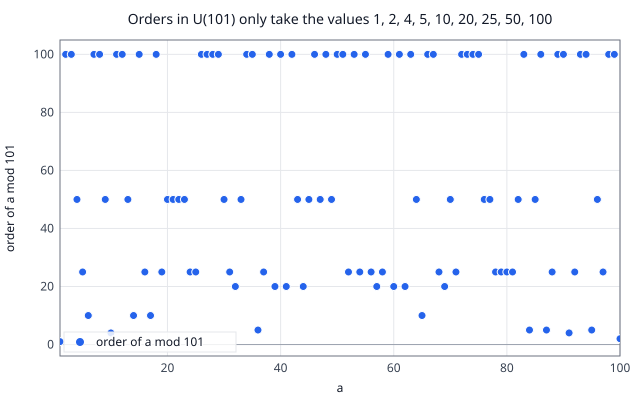

> `labels` (see `title`): A copy of plot p with a title or axis labels.

[1, 2, 4, 5, 10, 20, 25, 50, 100]

> `divisors`: All divisors of n, their sum, and Euler's phi: how many of 1..n share no factor with n (eulerphi is the same).

In [10]:
O = table([a, multorder(a, 101)], a, 1, 100);
labels(title(legend(scatter(O, [a order]), "order of a mod 101"), "Orders in U(101) only take the values 1, 2, 4, 5, 10, 20, 25, 50, 100"), "a", "order of a mod 101")
divisors(100)

The points lie on only a few horizontal lines, at the divisors of 100. The top line, order 100, holds the
primitive roots, $\varphi(100) = 40$ of them, and only $a = 1$ has order 1 and $a = 100 \equiv -1$ order 2. This is
why $a^{p-1} \equiv 1$ (Fermat's little theorem): the order of $a$ divides $p - 1$.

In [11]:
totient(100)

40

> `totient` (see `divisors`): All divisors of n, their sum, and Euler's phi: how many of 1..n share no factor with n (eulerphi is the same).

## 5. Roots of unity

The complex numbers $\omega^k$ with $\omega = e^{2\pi i/n}$ are the corners of a regular $n$-gon on the unit circle
(foundations lesson 6). Multiplying by $\omega$ rotates by $360^\circ/n$, so they form a cyclic group of size $n$ under
multiplication, isomorphic to $\mathbb{Z}_n$: $\omega^a \omega^b = \omega^{a + b}$, and the exponents add mod $n$. For
$n = 6$ (`expand` multiplies out the products of square roots):

In [12]:
w = exp(2*pi*i/6)
expand(w^2*w^3)
expand(w^5)
expand(w^6)

1/2+sqrt(3)*i/2

> `exp`: Exponential function.

1/2-sqrt(3)*i/2

> `expand`: Multiplies out products and powers.

1/2-sqrt(3)*i/2

> `expand`: Multiplies out products and powers.

1

> `expand`: Multiplies out products and powers.

$\omega^2\omega^3 = \omega^5$, and $\omega^6 = 1$: one more rotation and you are back.

## Summary

* A cyclic group is generated by one element. With $n$ elements it is isomorphic to $\mathbb{Z}_n$, addition mod $n$.
* In $\mathbb{Z}_n$, $k$ has order $n/\gcd(k, n)$; the generators are the $\varphi(n)$ numbers with $\gcd(k, n) = 1$.
* One subgroup for each divisor of $n$.
* $U(n)$: the invertible remainders under multiplication; cyclic exactly when there is a primitive root. $U(8)$ is the
  Klein four-group.
* The $n$-th roots of unity are a cyclic group.

**Try it:** list the orders of all elements of $U(15)$. Is it cyclic? Compare $\mathbb{Z}_6$ with $\mathbb{Z}_2\times
\mathbb{Z}_3$ (pairs added mod 2 and mod 3): the element $(1, 1)$ has order 6. Why does that make them isomorphic, and
what does it have to do with the Chinese remainder theorem?

Next: [Permutations and Lagrange's theorem](03-permutations-and-lagrange.ipynb).

## Sources

1. C. F. Gauss, *Disquisitiones Arithmeticae* (1801), Section 3 (primitive roots: $U(p)$ is cyclic).
2. J. A. Gallian, *Contemporary Abstract Algebra*, 9th ed., Cengage (2017). Chapters 2–4.
3. N. Carter, *Visual Group Theory*, Mathematical Association of America (2009). Chapter 5.